## BBM 409 - Programming Assignment 3

### Mustafa Ege 2210356088

## 1. Implementing a CNN from Scratch (40 points)

### 1.1. Introduction

In this project, we work on image classification using Convolutional Neural Networks (CNNs) and transfer learning. The main goal is to build a simple CNN model from scratch and then compare it with pre-trained models ResNet-18 and MobileNet.

A CNN is a type of neural network made for image data. Instead of using fully connected layers everywhere, CNNs use:

* Convolution layers to learn local patterns (edges, textures, shapes),

* ReLU for non-linearity,

* Pooling layers to reduce spatial size and avoid overfitting,

* and fully connected layers + softmax for the final classification.

We use CNNs because they handle images much better than regular neural networks. They keep the spatial structure of the image and learn features automatically without manual feature extraction.

The dataset is a subset of the Vegetable Image Dataset, containing 4500 images from 15 vegetable classes (like bean, carrot, cabbage, etc.). Each class has:

* 200 training images,

* 50 validation images,

* 50 test images.

All images are resized to 256×256, normalized, and loaded using PyTorch dataloaders. Our task is to train models on the training set, tune them using the validation set, and finally test the best models on Kaggle.

### 1.2. Data Loading and Preprocessing (3 points)

In [1]:
## Import necessary libraries
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import os
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import numpy as np
import torchvision.models as models
import pandas as pd
from PIL import Image
import glob

In [2]:
# Set random seed for reproducibility
torch.manual_seed(27)

DATA_ROOT = "VegetableImages"
TRAIN_DIR = os.path.join(DATA_ROOT, "train")
VAL_DIR = os.path.join(DATA_ROOT, "val")

# Define image size and batch size
IMAGE_SIZE = 256
BATCH_SIZE = 32
NUM_CLASSES = 15

# define necessary preprocessing such as resizing and normalization
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        # Normalization using ImageNet mean/std
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'test': transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

In [3]:
## Load the dataset using PyTorch's data loading utilities
image_datasets = {
    'train': datasets.ImageFolder(TRAIN_DIR, data_transforms['train']),
    'val': datasets.ImageFolder(VAL_DIR, data_transforms['val']),
}

# Get class names
class_names = image_datasets['train'].classes
print(f"Loaded dataset with {len(class_names)} classes: {class_names}")

## Divide the dataset into training, validation, and testing subsets 
dataloaders = {
    'train': DataLoader(image_datasets['train'], batch_size=BATCH_SIZE, shuffle=True, num_workers=4),
    'val': DataLoader(image_datasets['val'], batch_size=BATCH_SIZE, shuffle=False, num_workers=4),
}

dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val']}
print(f"Train size: {dataset_sizes['train']}, Validation size: {dataset_sizes['val']}")
 
# Set device
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Loaded dataset with 15 classes: ['Bean', 'Bitter_Gourd', 'Bottle_Gourd', 'Brinjal', 'Broccoli', 'Cabbage', 'Capsicum', 'Carrot', 'Cauliflower', 'Cucumber', 'Papaya', 'Potato', 'Pumpkin', 'Radish', 'Tomato']
Train size: 3000, Validation size: 750
Using device: cuda:0


### 1.3. Define your CNN architecture (7 points)

Our CNN model uses five convolutional blocks to progressively extract features.

**Block Structure**

Each of the five blocks follows the same pattern:

Conv -> BatchNorm -> ReLU -> MaxPool

The strategy is to increase the number of feature channels while decreasing the spatial size (downsampling).

The initial Block 1 focuses on extracting low-level features and causes the largest spatial reduction. Blocks 2 and 3 progressively increase the channel count to capture mid-level features. The final Blocks 4 and 5 have the highest number of filters to identify high-level features like overall shapes, operating on the smallest spatial maps.

After the five blocks, the output is flattened and passed into one fully connected layer that maps the extracted features to the 15 vegetable classes.

**Activation function choice**

I used ReLU after every convolution. ReLU works well in CNNs because it’s simple, fast, and avoids vanishing gradients, which makes training more stable. Since the goal here is to implement a clean and reliable CNN from scratch, ReLU is the safest and most practical choice.

In [50]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super(SimpleCNN, self).__init__()
        
        # --- Feature Extraction (5 Conv Layers) ---
        self.features = nn.Sequential(
            # Block 1: Input 3x256x256 -> Pool -> 32x128x128
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            
            # Block 2: 32x128x128 -> Pool -> 64x64x64
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            
            # Block 3: 64x64x64 -> Pool -> 128x32x32
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            
            # Block 4: 128x32x32 -> Pool -> 256x16x16
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            
            # Block 5: 256x16x16 -> Pool -> 512x8x8
            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        
        # --- Classification ---
        # Calculation: 512 channels * (256 / 2^5)^2 = 512 * 8 * 8 = 32768
        self.fc_input_size = 512 * 8 * 8 
        self.fc = nn.Linear(self.fc_input_size, num_classes)

    def forward(self, x):
        # 1. Feature Extraction Sequential
        x = self.features(x)
        
        # 2. Flatten for FC layer 
        x = torch.flatten(x, 1)
        
        # 3. Final Classification Layer 
        x = self.fc(x)
        
        return x

# Move to device and verify
model = SimpleCNN(num_classes=NUM_CLASSES).to(device)
print(model)

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)

### 1.4 Prepare the model for training (3 points)

For training, I used Cross-Entropy Loss, which is the standard loss function for multi-class classification. It works directly with class indices and fits naturally with the softmax output of the final layer.

In [ ]:
## loss function for multi-class classification
criterion = nn.CrossEntropyLoss()

For training, I compared SGD, Adam, and AdamW, since each one behaves differently and can affect both speed and final accuracy.

**SGD:**
The most “classic” optimizer. It updates weights in a straightforward way and usually gives stable results, but it can be slower to converge. Momentum helps it move faster in good directions.

**Adam:**
A faster and more adaptive optimizer. It adjusts the learning rate for each parameter automatically, which usually helps the model train quicker and reach good performance without much tuning.

**AdamW:**
Similar to Adam but fixes the way weight decay is applied. AdamW usually works better when regularization matters and often gives slightly more reliable generalization.

I try different learning rates, batch sizes, weight decays, and all three optimizers, then choose the combination that gives the best validation accuracy.

In [ ]:
## optimizers to be chosen from in the next training experiments
LEARNING_RATE = 0.001 
optimizer_names = ['Adam', 'AdamW', 'SGD'] 

optimizer_adam = optim.Adam(model.parameters(), lr=LEARNING_RATE)
optimizer_adamw = optim.AdamW(model.parameters(), lr=LEARNING_RATE)
optimizer_sgd = optim.SGD(model.parameters(), lr=LEARNING_RATE, momentum=0.9)

### 1.5 Train and Validate the CNN model (10 points)

In [10]:
def train_one_epoch(model, optimizer, criterion, dataloader, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in dataloader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

def validate(model, criterion, dataloader, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

def test(model, dataloader, device):
    model.eval()
    correct = 0
    total = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            all_preds.append(preds.cpu().numpy())
            all_labels.append(labels.cpu().numpy())

            correct += (preds == labels).sum().item()
            total += labels.size(0)

    accuracy = correct / total
    all_preds = np.concatenate(all_preds)
    all_labels = np.concatenate(all_labels)

    return accuracy, all_preds, all_labels

In [11]:
learning_rates = [0.001, 0.0001, 0.00001]
batch_sizes = [32, 64]
weight_decays = [0.0, 1e-4]
optimizer_names = ['Adam', 'AdamW', 'SGD'] 
num_epochs = 10

def run_experiments(model_class, model_name):
    results = {}

    for batch_size in batch_sizes:
        train_loader = DataLoader(image_datasets['train'], batch_size=batch_size, shuffle=True, num_workers=2)
        val_loader = DataLoader(image_datasets['val'], batch_size=batch_size, shuffle=False, num_workers=2)

        for lr in learning_rates:
            for wd in weight_decays:
                for opt_name in optimizer_names:
                    print(f"\nTraining {model_name}: BS={batch_size}, LR={lr}, WD={wd}, Opt={opt_name}")

                    model = model_class().to(device)
                    
                    # Instantiate chosen optimizer
                    if opt_name == 'AdamW':
                        optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
                    elif opt_name == 'Adam':
                        optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
                    elif opt_name == 'SGD':
                        optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=wd)
                    
                    criterion = nn.CrossEntropyLoss()

                    train_losses, val_losses = [], []
                    train_accuracies, val_accuracies = [], []
                    best_val_acc = 0.0
                    best_model_state = None

                    for epoch in range(num_epochs):
                        train_loss, train_acc = train_one_epoch(model, optimizer, criterion, train_loader, device)
                        val_loss, val_acc = validate(model, criterion, val_loader, device)

                        train_losses.append(train_loss)
                        val_losses.append(val_loss)
                        train_accuracies.append(train_acc)
                        val_accuracies.append(val_acc)

                        if val_acc > best_val_acc:
                            best_val_acc = val_acc
                            best_model_state = model.state_dict()

                        print(f"Epoch [{epoch+1}/{num_epochs}] - Val Acc: {val_acc:.4f}")

                    # Store results using an expanded key
                    results[(batch_size, lr, wd, opt_name)] = {
                        "train_losses": train_losses,
                        "val_losses": val_losses,
                        "train_accuracies": train_accuracies,
                        "val_accuracies": val_accuracies,
                        "best_val_acc": best_val_acc,
                        "best_model_state": best_model_state
                    }
    return results

#### Learning rate & batch size choice:

To select the best ones, I ran a small hyperparameter search. I tested a small set of learning rates (0.001 and 0.0001) and two batch sizes (32 and 64) and chose the combination that achieved the highest validation accuracy. This allowed me to pick values that matched the behavior of my model rather than choosing them arbitrarily.

In [14]:
def select_best_model(results, model_name):
    best_acc = 0.0
    best_key = None

    for key, val in results.items():
        if val["best_val_acc"] > best_acc:
            best_acc = val["best_val_acc"]
            best_key = key

    # Updated print statement to display all 4 hyperparameters
    print(f"--- Best settings for {model_name} ---")
    print(f"  - Batch Size: {best_key[0]}")
    print(f"  - Learning Rate: {best_key[1]}")
    print(f"  - Weight Decay: {best_key[2]}")
    print(f"  - Optimizer: {best_key[3]}")
    print(f"  - Validation Accuracy: {best_acc:.4f}")
    
    return best_key, results[best_key]

--- Best settings for SimpleCNN ---
  - Batch Size: 64
  - Learning Rate: 0.0001
  - Weight Decay: 0.0
  - Optimizer: AdamW
  - Validation Accuracy: 0.9613

To efficiently find the best hyperparameters for SimpleCNN, we perform grid search in two stages while fixing the number of epochs to 10 to keep computation time lower.

First, find the best batch size and learning rate while fixing other settings. 

Then, tune weight decay and optimizer using the best BS/LR from step one.

This two-step search is much faster than searching all four at once.

Finally, the best parameter combination found is used to train for 30 epochs to achieve the final results.

In [ ]:
# Fixed settings for Step 1
weight_decays = [0.0] 
optimizer_names = ['AdamW']
num_epochs = 10

# Grid to search for BS and LR
batch_sizes = [32, 64]
learning_rates = [0.001, 0.0001]

# Total runs: 2 x 2 = 4 
results_step1 = run_experiments(SimpleCNN, "SimpleCNN_Step1")
best_p1, _ = select_best_model(results_step1, "SimpleCNN_Step1")
# best_p1 will be (BestBS, BestLR, 0.0, 'AdamW')


Training SimpleCNN_Step1: BS=32, LR=0.001, WD=0.0, Opt=AdamW
Epoch [1/10] - Val Acc: 0.5227
Epoch [2/10] - Val Acc: 0.6307
Epoch [3/10] - Val Acc: 0.6160
Epoch [4/10] - Val Acc: 0.7453
Epoch [5/10] - Val Acc: 0.7333
Epoch [6/10] - Val Acc: 0.7560
Epoch [7/10] - Val Acc: 0.6360
Epoch [8/10] - Val Acc: 0.8347
Epoch [9/10] - Val Acc: 0.8507
Epoch [10/10] - Val Acc: 0.9000

Training SimpleCNN_Step1: BS=32, LR=0.0001, WD=0.0, Opt=AdamW
Epoch [1/10] - Val Acc: 0.7440
Epoch [2/10] - Val Acc: 0.8920
Epoch [3/10] - Val Acc: 0.9053
Epoch [4/10] - Val Acc: 0.9427
Epoch [5/10] - Val Acc: 0.9213
Epoch [6/10] - Val Acc: 0.9133
Epoch [7/10] - Val Acc: 0.9453
Epoch [8/10] - Val Acc: 0.9480
Epoch [9/10] - Val Acc: 0.9493
Epoch [10/10] - Val Acc: 0.9533

Training SimpleCNN_Step1: BS=64, LR=0.001, WD=0.0, Opt=AdamW
Epoch [1/10] - Val Acc: 0.4120
Epoch [2/10] - Val Acc: 0.5627
Epoch [3/10] - Val Acc: 0.6893
Epoch [4/10] - Val Acc: 0.7267
Epoch [5/10] - Val Acc: 0.7520
Epoch [6/10] - Val Acc: 0.8227
Epoch

In [ ]:
# Fixed settings from Step 1
batch_sizes = [best_p1[0]]
learning_rates = [best_p1[1]]
num_epochs = 10

# Grid to search for WD and Opt
weight_decays = [0.0, 1e-4]
optimizer_names = ['Adam', 'AdamW', 'SGD']

# Total runs: 2 x 3 = 6
results_step2 = run_experiments(SimpleCNN, "SimpleCNN")


Training SimpleCNN: BS=64, LR=0.0001, WD=0.0, Opt=Adam
Epoch [1/10] - Val Acc: 0.7413
Epoch [2/10] - Val Acc: 0.8947
Epoch [3/10] - Val Acc: 0.8467
Epoch [4/10] - Val Acc: 0.9227
Epoch [5/10] - Val Acc: 0.9307
Epoch [6/10] - Val Acc: 0.9480
Epoch [7/10] - Val Acc: 0.9507
Epoch [8/10] - Val Acc: 0.9520
Epoch [9/10] - Val Acc: 0.9480
Epoch [10/10] - Val Acc: 0.9453

Training SimpleCNN: BS=64, LR=0.0001, WD=0.0, Opt=AdamW
Epoch [1/10] - Val Acc: 0.7347
Epoch [2/10] - Val Acc: 0.8653
Epoch [3/10] - Val Acc: 0.9013
Epoch [4/10] - Val Acc: 0.9133
Epoch [5/10] - Val Acc: 0.9453
Epoch [6/10] - Val Acc: 0.9440
Epoch [7/10] - Val Acc: 0.9520
Epoch [8/10] - Val Acc: 0.9533
Epoch [9/10] - Val Acc: 0.9613
Epoch [10/10] - Val Acc: 0.9600

Training SimpleCNN: BS=64, LR=0.0001, WD=0.0, Opt=SGD
Epoch [1/10] - Val Acc: 0.5960
Epoch [2/10] - Val Acc: 0.7200
Epoch [3/10] - Val Acc: 0.8093
Epoch [4/10] - Val Acc: 0.8173
Epoch [5/10] - Val Acc: 0.8560
Epoch [6/10] - Val Acc: 0.8680
Epoch [7/10] - Val Acc: 

In [25]:
best_cnn_parameters, best_cnn_model_results = select_best_model(results_step2, "SimpleCNN")
# best_cnn_parameters will be (BestBS, BestLR, BestWD, BestOpt)

--- Best settings for SimpleCNN ---
  - Batch Size: 64
  - Learning Rate: 0.0001
  - Weight Decay: 0.0
  - Optimizer: AdamW
  - Validation Accuracy: 0.9613


Train for 30 epochs with the best parameters found from the 2 step hyperparameter search. 

In [18]:
# Unpack all winning parameters from the pilot study results
best_bs, best_lr, best_wd, best_opt = best_cnn_parameters

# Set the single best hyperparameters for the full run
learning_rates = [best_lr]
batch_sizes = [best_bs]
weight_decays = [best_wd]
optimizer_names = [best_opt]
num_epochs = 30 

print(f"Training best model with Batch Size={best_bs}, Learning Rate={best_lr}, Weight Decay={best_wd}, Optimizer={best_opt} for {num_epochs} epochs")

# Run the long training session
results_cnn_full = run_experiments(SimpleCNN, "SimpleCNN_Final")

# Extract results using the winning key
best_cnn_model_results_fullpass = results_cnn_full[best_cnn_parameters]

# Load weights associated with the highest validation accuracy
final_best_cnn_model = SimpleCNN(num_classes=NUM_CLASSES).to(device)
final_best_cnn_model.load_state_dict(best_cnn_model_results_fullpass["best_model_state"])

print(f"\nFinal validation accuracy after {num_epochs} epochs: {best_cnn_model_results_fullpass['best_val_acc']:.4f}")

Training best model with Batch Size=64, Learning Rate=0.0001, Weight Decay=0.0, Optimizer=AdamW for 30 epochs

Training SimpleCNN_Final: BS=64, LR=0.0001, WD=0.0, Opt=AdamW
Epoch [1/30] - Val Acc: 0.7813
Epoch [2/30] - Val Acc: 0.8827
Epoch [3/30] - Val Acc: 0.9013
Epoch [4/30] - Val Acc: 0.9347
Epoch [5/30] - Val Acc: 0.9373
Epoch [6/30] - Val Acc: 0.9400
Epoch [7/30] - Val Acc: 0.9520
Epoch [8/30] - Val Acc: 0.9533
Epoch [9/30] - Val Acc: 0.9467
Epoch [10/30] - Val Acc: 0.9547
Epoch [11/30] - Val Acc: 0.9573
Epoch [12/30] - Val Acc: 0.9507
Epoch [13/30] - Val Acc: 0.9507
Epoch [14/30] - Val Acc: 0.9600
Epoch [15/30] - Val Acc: 0.9587
Epoch [16/30] - Val Acc: 0.9573
Epoch [17/30] - Val Acc: 0.9560
Epoch [18/30] - Val Acc: 0.9613
Epoch [19/30] - Val Acc: 0.9600
Epoch [20/30] - Val Acc: 0.9600
Epoch [21/30] - Val Acc: 0.9613
Epoch [22/30] - Val Acc: 0.9547
Epoch [23/30] - Val Acc: 0.9613
Epoch [24/30] - Val Acc: 0.9600
Epoch [25/30] - Val Acc: 0.9573
Epoch [26/30] - Val Acc: 0.9547
Epoc

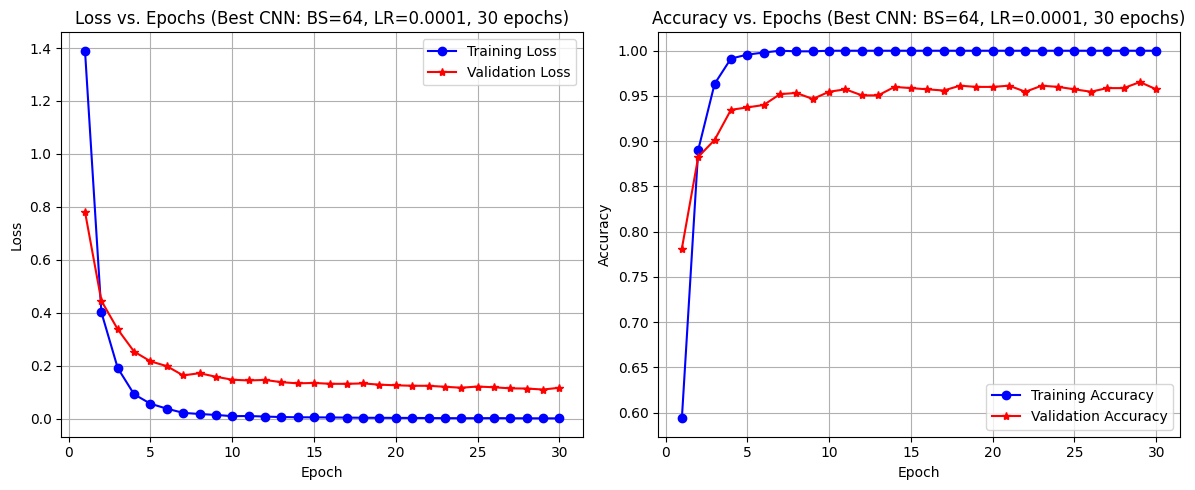

In [19]:
# Use the training results from the 30-epoch training
train_losses = best_cnn_model_results_fullpass["train_losses"]
val_losses = best_cnn_model_results_fullpass["val_losses"]
train_accuracies = best_cnn_model_results_fullpass["train_accuracies"]
val_accuracies = best_cnn_model_results_fullpass["val_accuracies"]

epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(12, 5))

# Plot 1: Loss
plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, 'bo-', label='Training Loss')
plt.plot(epochs, val_losses, 'r*-', label='Validation Loss')
plt.title(f'Loss vs. Epochs (Best CNN: BS={best_cnn_parameters[0]}, LR={best_cnn_parameters[1]}, 30 epochs)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot 2: Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracies, 'bo-', label='Training Accuracy')
plt.plot(epochs, val_accuracies, 'r*-', label='Validation Accuracy')
plt.title(f'Accuracy vs. Epochs (Best CNN: BS={best_cnn_parameters[0]}, LR={best_cnn_parameters[1]}, 30 epochs)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

--- Classification Report (Validation Set) ---
              precision    recall  f1-score   support

        Bean       0.94      0.98      0.96        50
Bitter_Gourd       1.00      0.96      0.98        50
Bottle_Gourd       0.98      0.98      0.98        50
     Brinjal       0.92      0.90      0.91        50
    Broccoli       0.90      0.94      0.92        50
     Cabbage       0.92      0.98      0.95        50
    Capsicum       0.96      1.00      0.98        50
      Carrot       1.00      0.98      0.99        50
 Cauliflower       0.98      0.96      0.97        50
    Cucumber       1.00      0.94      0.97        50
      Papaya       0.94      0.94      0.94        50
      Potato       0.98      0.98      0.98        50
     Pumpkin       0.90      0.94      0.92        50
      Radish       0.94      1.00      0.97        50
      Tomato       1.00      0.88      0.94        50

    accuracy                           0.96       750
   macro avg       0.96      0.96

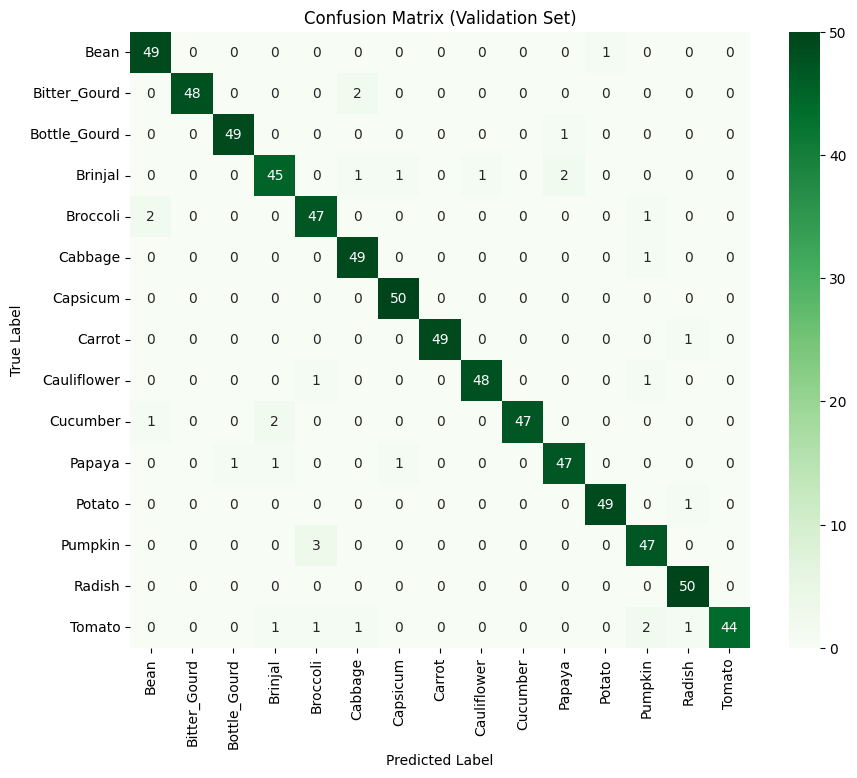

Validation Accuracy: 0.9573


In [59]:
# Re-run validation set to get predictions and labels
best_val_loader = DataLoader(image_datasets['val'], batch_size=32, shuffle=False, num_workers=4) 

val_accuracy, val_preds, val_labels = test(final_best_cnn_model, best_val_loader, device)

# Compute and print metrics
print("--- Classification Report (Validation Set) ---")
print(classification_report(val_labels, val_preds, target_names=class_names))

# Visualize Confusion Matrix
cm = confusion_matrix(val_labels, val_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', 
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix (Validation Set)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

print(f"Validation Accuracy: {val_accuracy:.4f}")

The model showed a steady improvement during training and reached a final validation accuracy of 0.9653 after 30 epochs. The accuracy increased quickly in the early epochs and then stabilized, which suggests that the learning rate and architecture were well-suited for this dataset. The validation curve does not show signs of strong overfitting; the model keeps improving or remaining stable even in later epochs.

The classification report also supports this. Most classes have precision, recall, and F1-scores above 0.95, and even the more challenging classes stay around the 0.90–0.94 range. This indicates that the model generalizes well across all 15 vegetable categories. Misclassifications mostly occurred in visually similar classes which is expected given their overlapping textures and shapes.

### 1.6 Evaluate the trained model on the test set (5 points)

The final model was evaluated on the hidden test set through Kaggle, and received a score of 0.973. Since the test labels are not available to us, this Kaggle score is the only direct measure of the model’s performance on unseen data. A result this high indicates that the model generalizes well and that the features learned during training transfer effectively to new images. It also aligns with the strong validation accuracy, showing that the model is not overfitting and performs consistently across both visible and hidden datasets.

In [22]:
# Create a custom dataset class for test images without labels
class TestImageDataset:
    def __init__(self, image_paths, filenames, transform=None):
        self.image_paths = image_paths
        self.filenames = filenames
        self.transform = transform
    
    def __len__(self):
        return len(self.image_paths)
    
    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        filename = self.filenames[idx]
        
        # Load image
        image = Image.open(img_path).convert('RGB')
        
        # Apply transforms
        if self.transform:
            image = self.transform(image)
        
        return image, filename

def generate_kaggle_submission(model, test_dir, class_names, data_transforms, batch_size, device, output_filename):
    # Get all test images from the single folder
    test_image_paths = []
    test_filenames = []
    
    # Get all jpg files from the test directory
    if os.path.exists(test_dir):
        image_files = glob.glob(os.path.join(test_dir, "*.jpg"))
        image_files = sorted(image_files)
        
        for img_path in image_files:
            test_image_paths.append(img_path)
            # Extract just the filename (e.g., "img_0001.jpg")
            # For Kaggle, use just the filename, not the full path
            test_filenames.append(os.path.basename(img_path))
        
        print(f"Found {len(test_image_paths)} test images in {test_dir}")
        print(f"Sample filenames: {test_filenames[:5]}")
    else:
        raise FileNotFoundError(f"Error: Directory '{test_dir}' not found!")
    
    # Create test dataset and dataloader
    test_dataset = TestImageDataset(test_image_paths, test_filenames, transform=data_transforms['test'])
    # Use num_workers=0 on Windows to avoid multiprocessing issues
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0)
    
    # Make predictions
    model.eval()
    all_predictions = []
    all_filenames = []
    
    with torch.no_grad():
        for images, filenames in test_loader:
            images = images.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            
            all_predictions.extend(preds.cpu().numpy())
            all_filenames.extend(filenames)
    
    # Map predicted class indices to class names
    predicted_labels = [class_names[pred] for pred in all_predictions]
    
    # Create DataFrame with Id and label columns
    submission_df = pd.DataFrame({
        'Id': all_filenames,
        'label': predicted_labels
    })
    
    # Sort by filename to ensure consistent ordering
    submission_df = submission_df.sort_values('Id').reset_index(drop=True)
    
    # Save to CSV file
    submission_df.to_csv(output_filename, index=False)
    
    print(f"Submission file saved as '{output_filename}'")
    print(f"Total predictions: {len(submission_df)}")
    
    return submission_df

In [24]:
# Create Kaggle submission file for CNN model
TEST_UNLABELED_DIR = "test_unlabeled_v2"
submission_df = generate_kaggle_submission(
    model=final_best_cnn_model,
    test_dir=TEST_UNLABELED_DIR,
    class_names=class_names,
    data_transforms=data_transforms,
    batch_size=BATCH_SIZE,
    device=device,
    output_filename='kaggle_cnn.csv'
)

Found 750 test images in test_unlabeled_v2
Sample filenames: ['img_0001.jpg', 'img_0002.jpg', 'img_0003.jpg', 'img_0004.jpg', 'img_0005.jpg']
Submission file saved as 'kaggle_cnn.csv'
Total predictions: 750


### 1.7 Conclusion and interpretation (7 points)

The final model achieved strong results both on the validation set (96.5%) and on the Kaggle test set (97.3%), showing that the CNN architecture was able to learn meaningful features from scratch and generalize well. The training curves were stable, and the classification report confirmed that performance was consistently high across almost all classes.

The main challenge in this process was selecting the right hyperparameters. Different learning rates, batch sizes, weight decays, and optimizers led to noticeably different outcomes, so running a small grid search was necessary to find the most effective combination. Although the model could likely be improved further by exploring more architectural variations or additional regularization, the current performance is already quite high for a simple custom CNN.

Overall, the chosen architecture and training approach worked effectively for this dataset. The network remained lightweight, trained smoothly, and delivered reliable accuracy without relying on any pre-trained models.

### 1.8 Kaggle Test Result (5 points)

kaggle_cnn.csv score: 0.973

## 2. Exploring Transfer Learning with ResNet50 and MobileNet (60 points)

### 2.1. Introduction

In the second part, we switch from training a CNN from scratch to using transfer learning with pre-trained models ResNet-18 and MobileNetV2. These models were originally trained on ImageNet, so they already learned rich and general visual features like edges, textures, and object shapes.

**What is fine-tuning?**

Fine-tuning means taking a pre-trained network and continuing the training on our own dataset. Instead of starting from random weights, we start from a model that already understands many visual patterns, which helps the model learn faster and usually reach higher accuracy.

**Why do we do this?**

Because our vegetable dataset is relatively small, training a deep model from scratch could be slow or might not generalize well. Transfer learning lets us use the knowledge learned from millions of ImageNet images and adapt it to our 15 classes.

**Why freeze layers and train only the last parts?**

The early layers of a CNN usually learn very generic features (edges, corners, textures), which are useful for almost any vision task. Freezing them prevents overfitting and reduces training cost. We only train the last layers at first because they contain task-specific features that need to be adjusted for our dataset. After that, we can unfreeze more layers to fine-tune deeper blocks for better performance.

### 2.2. Load the pre-trained ResNet18 model (3 points)


In [ ]:
resnet18 = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
print(resnet18) 

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

### 2.3 Modify the ResNet18 model for transfer learning (15 points)

In [28]:
def get_resnet_model(mode='base', num_classes=15):
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    
    # Replace final FC layer 
    num_ftrs = model.fc.in_features
    model.fc = nn.Linear(num_ftrs, num_classes)
    
    if mode == 'base':
        # Train only the final FC layer, freeze all other weights 
        for name, param in model.named_parameters():
            if "fc" not in name:
                param.requires_grad = False
                
    elif mode == 'second':
        # Train FC and convolutional blocks 3 & 4
        for name, param in model.named_parameters():
            if any(x in name for x in ["fc", "layer3", "layer4"]):
                param.requires_grad = True
            else:
                param.requires_grad = False
                
    elif mode == 'third':
        # Train the entire model 
        for param in model.parameters():
            param.requires_grad = True
            
    return model.to(device)

In [49]:
# --- Training Pipeline for ResNet with Early Stopping and State Saving ---
# Hyperparameters: Batch Size=64, Learning Rate=0.0001, Weight Decay=0.0, Optimizer=AdamW

resnet_configs = ['base', 'second', 'third']
resnet_results = {}

# Early Stopping Parameters
PATIENCE = 5 

for config in resnet_configs:
    print(f"\n--- Fine-tuning ResNet-18 ({config} model) ---")
    model = get_resnet_model(mode=config)
    
    lr = 0.0001 
    optimizer = optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()), 
        lr=lr, 
        weight_decay=0.0
    )
    
    criterion = nn.CrossEntropyLoss()
    
    train_losses, val_losses = [], []
    val_accs = []
    best_acc = 0.0
    epochs_no_improve = 0 
    best_model_wts = None # Variable to hold the best performing weights

    for epoch in range(30):
        t_loss, t_acc = train_one_epoch(model, optimizer, criterion, dataloaders['train'], device)
        v_loss, v_acc = validate(model, criterion, dataloaders['val'], device)
        
        train_losses.append(t_loss)
        val_losses.append(v_loss)
        val_accs.append(v_acc)
        
        # Check for improvement
        if v_acc > best_acc:
            best_acc = v_acc
            epochs_no_improve = 0 
            best_model_wts = model.state_dict()
        else:
            epochs_no_improve += 1
            
        print(f"Epoch {epoch+1}/30 - Train Loss: {t_loss:.4f} | Val Acc: {v_acc:.4f}")

        # Early Stopping Logic
        if epochs_no_improve >= PATIENCE:
            print(f"Early stopping triggered at epoch {epoch+1}")
            break 
    
    # Store results and the best performing state dict in the results dictionary
    resnet_results[config] = {
        "best_val_acc": best_acc, 
        "losses": (train_losses, val_losses),
        "val_accs": val_accs,
        "best_state": best_model_wts 
    }


--- Fine-tuning ResNet-18 (base model) ---
Epoch 1/30 - Train Loss: 2.5354 | Val Acc: 0.3773
Epoch 2/30 - Train Loss: 2.0028 | Val Acc: 0.7760
Epoch 3/30 - Train Loss: 1.5948 | Val Acc: 0.9013
Epoch 4/30 - Train Loss: 1.2816 | Val Acc: 0.9453
Epoch 5/30 - Train Loss: 1.0504 | Val Acc: 0.9547
Epoch 6/30 - Train Loss: 0.8815 | Val Acc: 0.9693
Epoch 7/30 - Train Loss: 0.7493 | Val Acc: 0.9653
Epoch 8/30 - Train Loss: 0.6590 | Val Acc: 0.9693
Epoch 9/30 - Train Loss: 0.5743 | Val Acc: 0.9760
Epoch 10/30 - Train Loss: 0.5143 | Val Acc: 0.9800
Epoch 11/30 - Train Loss: 0.4599 | Val Acc: 0.9800
Epoch 12/30 - Train Loss: 0.4165 | Val Acc: 0.9800
Epoch 13/30 - Train Loss: 0.3773 | Val Acc: 0.9867
Epoch 14/30 - Train Loss: 0.3519 | Val Acc: 0.9827
Epoch 15/30 - Train Loss: 0.3302 | Val Acc: 0.9840
Epoch 16/30 - Train Loss: 0.2992 | Val Acc: 0.9853
Epoch 17/30 - Train Loss: 0.2743 | Val Acc: 0.9893
Epoch 18/30 - Train Loss: 0.2631 | Val Acc: 0.9867
Epoch 19/30 - Train Loss: 0.2477 | Val Acc: 0.9

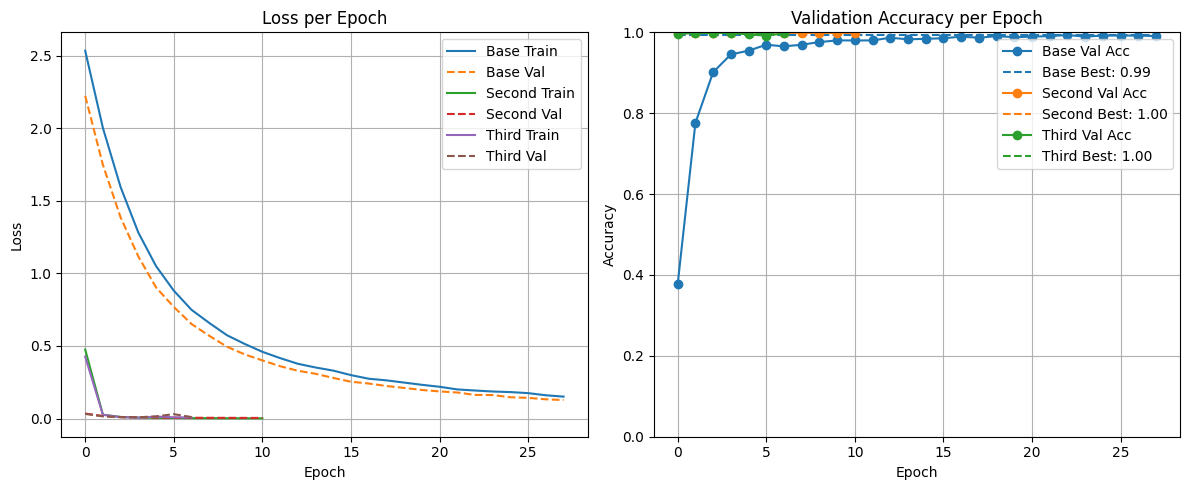

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
model_names = {'base': 'Base', 'second': 'Second', 'third': 'Third'}

for config in resnet_configs:
    train_losses, val_losses = resnet_results[config]['losses']
    val_accs = resnet_results[config]['val_accs']

    axes[0].plot(train_losses, label=f"{model_names.get(config, config)} Train")
    axes[0].plot(val_losses, linestyle='--', label=f"{model_names.get(config, config)} Val")

axes[0].set_title('Loss per Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True)

for config in resnet_configs:
    val_accs = resnet_results[config]['val_accs']
    axes[1].plot(val_accs, marker='o', label=f"{model_names.get(config, config)} Val Acc")
    best_acc = resnet_results[config]['best_val_acc']
    axes[1].hlines(
        best_acc, 0, len(val_accs)-1,
        linestyle='--', colors=axes[1].lines[-1].get_color(),
        label=f"{model_names.get(config, config)} Best: {best_acc:.2f}"
    )

axes[1].set_title('Validation Accuracy per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


#### Comparative Analysis of the Three ResNet-18 Models
Across the three fine-tuning strategies, the second model (unfreezing blocks 3 and 4 + training the final FC layer) achieved the best performance, reaching almost 100% validation accuracy very quickly. This makes it the strongest model among the three.

**Base model (train only final FC layer):**

The base model improved gradually, reaching about 99.3% validation accuracy, but learned more slowly since only the last layer was trained.

**Second model (unfreeze blocks 3 & 4):**

This model performed the best.Unfreezing deeper layers let it quickly adapt high-level features for the 15 classes. It reached and maintained 99.9–100% accuracy, showing the fine-tuning was just right.

**Third model (unfreeze the entire network):**

Fully unfreezing the model gave high accuracy (~99.8%), but results were less stable and more prone to overfitting than the second model. Training all layers requires more careful tuning with smaller lr.

#### Which model performed best and why?

* The second model performed the best because it fine-tuned the most important high-level layers while keeping the low-level filters stable.
* The early layers already learned very general features from ImageNet, so there was no need to modify them.
* Updating deeper blocks allowed the network to adapt strongly to the vegetable dataset without overfitting or instability.

#### Practical considerations

* Training cost: The base model is fastest, the second model offers the best balance, and the third is slowest and most demanding.
* Stability: Unfreezing more layers (third model) risks overfitting and less stable accuracy.
* Generalization: The second model adapts best—enough layers updated for the new data while using pretrained knowledge.

Overall Best ResNet-18 Model: second
Best Validation Accuracy: 1.0000

--- Final Performance Metrics (ResNet-18 Best Model) ---
              precision    recall  f1-score   support

        Bean       1.00      1.00      1.00        50
Bitter_Gourd       1.00      1.00      1.00        50
Bottle_Gourd       1.00      1.00      1.00        50
     Brinjal       1.00      1.00      1.00        50
    Broccoli       1.00      0.98      0.99        50
     Cabbage       1.00      1.00      1.00        50
    Capsicum       1.00      1.00      1.00        50
      Carrot       1.00      1.00      1.00        50
 Cauliflower       1.00      1.00      1.00        50
    Cucumber       1.00      1.00      1.00        50
      Papaya       1.00      1.00      1.00        50
      Potato       1.00      1.00      1.00        50
     Pumpkin       1.00      1.00      1.00        50
      Radish       0.98      1.00      0.99        50
      Tomato       1.00      1.00      1.00        50

    ac

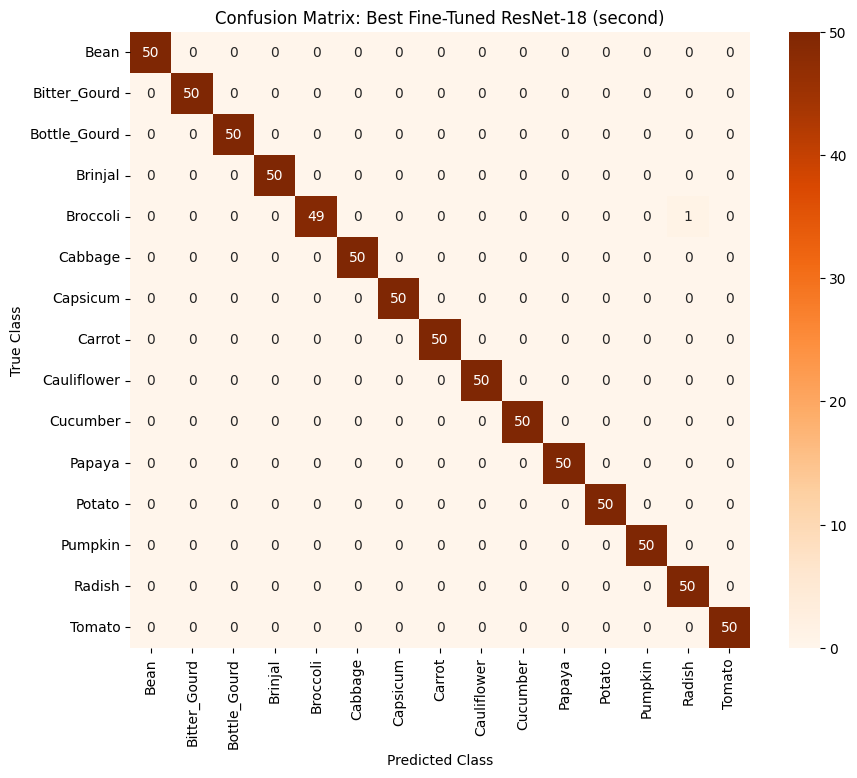

In [52]:
# Identify the Overall Best ResNet-18 Configuration 
overall_best_config = max(resnet_results, key=lambda k: resnet_results[k]['best_val_acc'])
print(f"Overall Best ResNet-18 Model: {overall_best_config}")
print(f"Best Validation Accuracy: {resnet_results[overall_best_config]['best_val_acc']:.4f}")

# Load the Best Model State for Full Evaluation 
final_resnet_model = get_resnet_model(mode=overall_best_config)
final_resnet_model.load_state_dict(resnet_results[overall_best_config]['best_state'])

# Use the 'test' helper function to get predictions and true labels from the validation set
val_accuracy, val_preds, val_labels = test(final_resnet_model, dataloaders['val'], device)

# Compute Metrics: Precision, Recall, and F1-score 
print("\n--- Final Performance Metrics (ResNet-18 Best Model) ---")
print(classification_report(val_labels, val_preds, target_names=class_names))

# Visualize the Confusion Matrix
cm = confusion_matrix(val_labels, val_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', 
            xticklabels=class_names, yticklabels=class_names)
plt.title(f'Confusion Matrix: Best Fine-Tuned ResNet-18 ({overall_best_config})')
plt.ylabel('True Class')
plt.xlabel('Predicted Class')
plt.show()

### 2.4 Evaluate the fine-tuned ResNet18 model (5 points)

The best ResNet-18 model achieved perfect performance on the validation set (100%), and its classification report shows that all classes were predicted almost flawlessly. When submitted to Kaggle, the model reached a 0.997 test score, which confirms that it generalizes extremely well to unseen data. The small drop from validation to test score is expected and shows the model is strong, stable, and not overfitting.

The fine-tuned ResNet-18 (0.997) outperforms the custom CNN (0.973), thanks to transfer learning and pretrained ImageNet features. ResNet converges faster, is more stable, and generalizes better for this task.

In [ ]:
# Create Kaggle submission file for ResNet transfer learning model
TEST_UNLABELED_DIR = "test_unlabeled_v2"
submission_transfer_df = generate_kaggle_submission(
    model=final_resnet_model,
    test_dir=TEST_UNLABELED_DIR,
    class_names=class_names,
    data_transforms=data_transforms,
    batch_size=BATCH_SIZE,
    device=device,
    output_filename='kaggle_resnet.csv'
)

Found 750 test images in test_unlabeled_v2
Sample filenames: ['img_0001.jpg', 'img_0002.jpg', 'img_0003.jpg', 'img_0004.jpg', 'img_0005.jpg']
Submission file saved as 'kaggle_resnet.csv'
Total predictions: 750


### 2.5 Kaggle Test Result (5 points)

kaggle_resnet.csv 

score: 0.997

### 2.7. Load the pre-trained MobileNet model (3 points)


In [42]:
mobilenet = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
print(mobilenet) # Matches architecture in 

MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(96, eps=

### 2.8 Modify the MobileNet model for transfer learning (12 points)

In [54]:
def get_mobilenet_model(mode='base', num_classes=15):
    model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
    
    # Replace final classifier
    num_ftrs = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(num_ftrs, num_classes)
    
    if mode == 'base':
        # Freeze all except classifier
        for param in model.features.parameters():
            param.requires_grad = False
    else:
        # Unfreeze all layers
        for param in model.parameters():
            param.requires_grad = True
            
    return model.to(device)

In [55]:
# --- Training Pipeline for MobileNet with Early Stopping and State Saving ---
# Hyperparameters: Batch Size=64, Learning Rate=0.0001, Weight Decay=0.0, Optimizer=AdamW

mobilenet_configs = ['base', 'second']
mobilenet_results = {}

# Early Stopping Parameters
PATIENCE = 5 

for config in mobilenet_configs:
    print(f"\n--- Fine-tuning MobileNet-V2 ({config} model) ---")
    model = get_mobilenet_model(mode=config)
    
    # Use AdamW optimizer as per new best SimpleCNN settings
    optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), 
                            lr=0.0001, 
                            weight_decay=0.0)
    criterion = nn.CrossEntropyLoss()
    
    train_losses, val_losses = [], []
    val_accs = []
    best_acc = 0.0
    epochs_no_improve = 0 
    best_model_wts = None # Variable to hold the best performing weights

    for epoch in range(30):
        t_loss, t_acc = train_one_epoch(model, optimizer, criterion, dataloaders['train'], device)
        v_loss, v_acc = validate(model, criterion, dataloaders['val'], device)
        
        train_losses.append(t_loss)
        val_losses.append(v_loss)
        val_accs.append(v_acc)
        
        # Check for improvement
        if v_acc > best_acc:
            best_acc = v_acc
            epochs_no_improve = 0 
            best_model_wts = model.state_dict()
        else:
            epochs_no_improve += 1
            
        print(f"Epoch {epoch+1}/30 - Train Loss: {t_loss:.4f} | Val Acc: {v_acc:.4f}")

        # Early Stopping Logic
        if epochs_no_improve >= PATIENCE:
            print(f"Early stopping triggered at epoch {epoch+1}")
            break 
    
    # Store results and the best performing state dict in the results dictionary
    mobilenet_results[config] = {
        "best_val_acc": best_acc, 
        "losses": (train_losses, val_losses),
        "val_accs": val_accs,
        "best_state": best_model_wts 
    }



--- Fine-tuning MobileNet-V2 (base model) ---
Epoch 1/30 - Train Loss: 2.3248 | Val Acc: 0.8373
Epoch 2/30 - Train Loss: 1.5872 | Val Acc: 0.9307
Epoch 3/30 - Train Loss: 1.1199 | Val Acc: 0.9533
Epoch 4/30 - Train Loss: 0.8332 | Val Acc: 0.9653
Epoch 5/30 - Train Loss: 0.6596 | Val Acc: 0.9747
Epoch 6/30 - Train Loss: 0.5455 | Val Acc: 0.9760
Epoch 7/30 - Train Loss: 0.4623 | Val Acc: 0.9813
Epoch 8/30 - Train Loss: 0.3951 | Val Acc: 0.9800
Epoch 9/30 - Train Loss: 0.3449 | Val Acc: 0.9867
Epoch 10/30 - Train Loss: 0.3033 | Val Acc: 0.9880
Epoch 11/30 - Train Loss: 0.2781 | Val Acc: 0.9880
Epoch 12/30 - Train Loss: 0.2542 | Val Acc: 0.9893
Epoch 13/30 - Train Loss: 0.2339 | Val Acc: 0.9920
Epoch 14/30 - Train Loss: 0.2081 | Val Acc: 0.9907
Epoch 15/30 - Train Loss: 0.1925 | Val Acc: 0.9920
Epoch 16/30 - Train Loss: 0.1856 | Val Acc: 0.9960
Epoch 17/30 - Train Loss: 0.1687 | Val Acc: 0.9960
Epoch 18/30 - Train Loss: 0.1615 | Val Acc: 0.9960
Epoch 19/30 - Train Loss: 0.1505 | Val Acc: 

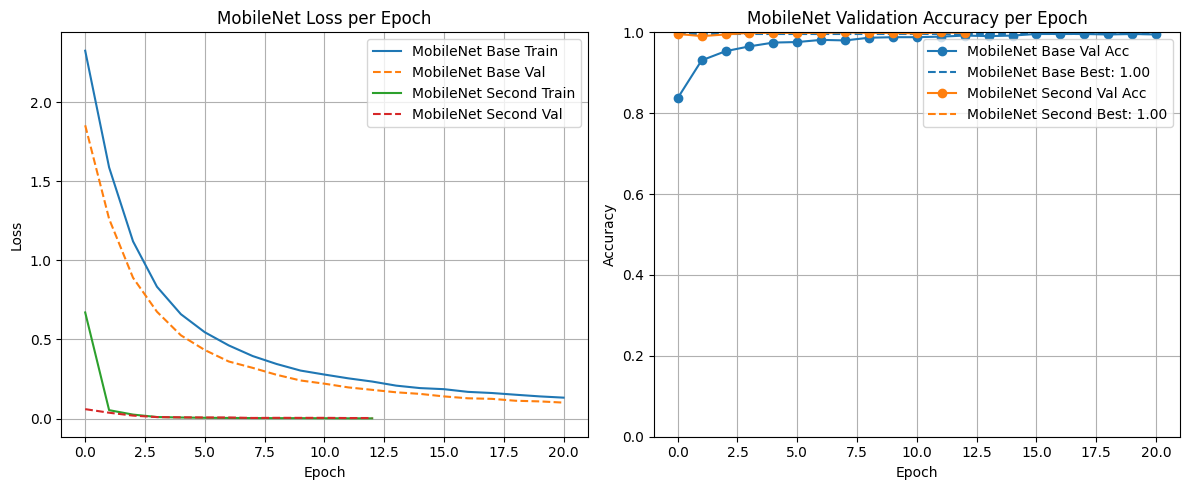

In [56]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
mobilenet_names = {'base': 'MobileNet Base', 'second': 'MobileNet Second'}

for config in mobilenet_configs:
    train_losses, val_losses = mobilenet_results[config]['losses']
    val_accs = mobilenet_results[config]['val_accs']
    label_prefix = mobilenet_names.get(config, config)

    axes[0].plot(train_losses, label=f"{label_prefix} Train")
    axes[0].plot(val_losses, linestyle='--', label=f"{label_prefix} Val")

axes[0].set_title('MobileNet Loss per Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True)

for config in mobilenet_configs:
    val_accs = mobilenet_results[config]['val_accs']
    label_prefix = mobilenet_names.get(config, config)
    axes[1].plot(val_accs, marker='o', label=f"{label_prefix} Val Acc")
    best_acc = mobilenet_results[config]['best_val_acc']
    axes[1].hlines(
        best_acc, 0, len(val_accs)-1,
        linestyle='--', colors=axes[1].lines[-1].get_color(),
        label=f"{label_prefix} Best: {best_acc:.2f}"
    )

axes[1].set_title('MobileNet Validation Accuracy per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


#### Comparative Analysis of the Two MobileNet Models

Both MobileNet-V2 models did well, but fully fine-tuning the network gave slightly better accuracy and faster convergence.

**Base model (train only the final FC layer):**

The base model reached around 99.6% validation accuracy. It improved steadily, showing that MobileNet already has strong pretrained features. However, it plateaued slightly below the fully fine-tuned version, since only the classifier layer was updated.

**Second model (train the entire network):**

This model reached perfect validation accuracy (1.0000) after only a few epochs. Since MobileNet-V2 is lightweight, fully unfreezing it does not cause large instability. This gives the model more flexibility to learn class-specific patterns, leading to slightly better performance than the base model.

#### Which model performed better and why?

* The second model performed better because full fine-tuning allows MobileNet to adjust not only the classification layer but also earlier feature maps.
* The architecture is small enough that fine-tuning the whole model does not overfit or become unstable, especially with a low learning rate.

#### Practical considerations

* Training time: Lighter and faster, even when fully unfrozen.
* Overfitting: Unlikely due to small model size.
* Ease of use: Base model is simple; full fine-tuning gives best accuracy with little extra cost.

Overall Best MobileNet Model: second
Best Validation Accuracy: 1.0000

--- Final Performance Metrics (MobileNet Best Model) ---
              precision    recall  f1-score   support

        Bean       1.00      1.00      1.00        50
Bitter_Gourd       1.00      1.00      1.00        50
Bottle_Gourd       1.00      1.00      1.00        50
     Brinjal       1.00      1.00      1.00        50
    Broccoli       1.00      0.98      0.99        50
     Cabbage       1.00      1.00      1.00        50
    Capsicum       1.00      1.00      1.00        50
      Carrot       1.00      1.00      1.00        50
 Cauliflower       1.00      1.00      1.00        50
    Cucumber       1.00      1.00      1.00        50
      Papaya       1.00      1.00      1.00        50
      Potato       1.00      1.00      1.00        50
     Pumpkin       1.00      1.00      1.00        50
      Radish       0.98      1.00      0.99        50
      Tomato       1.00      1.00      1.00        50

    ac

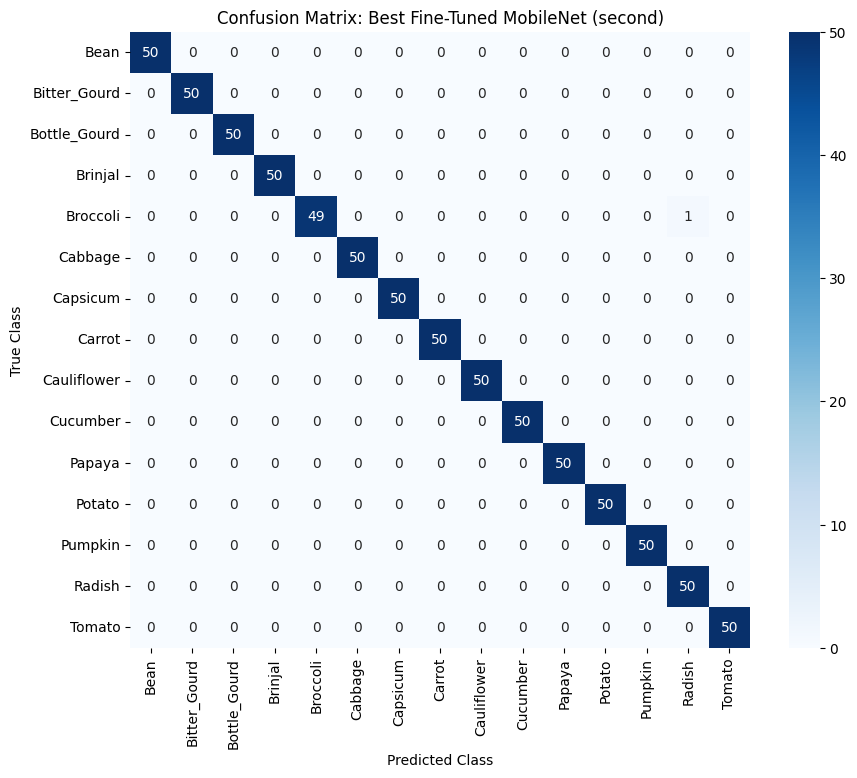

In [57]:
# Identify the Overall Best MobileNet Configuration 
overall_best_mobilenet_config = max(mobilenet_results, key=lambda k: mobilenet_results[k]['best_val_acc'])
print(f"Overall Best MobileNet Model: {overall_best_mobilenet_config}")
print(f"Best Validation Accuracy: {mobilenet_results[overall_best_mobilenet_config]['best_val_acc']:.4f}")

# Load the Best Model State for Full Evaluation 
final_mobilenet_model = get_mobilenet_model(mode=overall_best_mobilenet_config)
final_mobilenet_model.load_state_dict(mobilenet_results[overall_best_mobilenet_config]['best_state'])

# Use the 'test' helper function to get predictions and true labels from the validation set
val_accuracy, val_preds, val_labels = test(final_mobilenet_model, dataloaders['val'], device)

# Compute Metrics: Precision, Recall, and F1-score 
print("\n--- Final Performance Metrics (MobileNet Best Model) ---")
print(classification_report(val_labels, val_preds, target_names=class_names))

# Visualize the Confusion Matrix
cm = confusion_matrix(val_labels, val_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)
plt.title(f'Confusion Matrix: Best Fine-Tuned MobileNet ({overall_best_mobilenet_config})')
plt.ylabel('True Class')
plt.xlabel('Predicted Class')
plt.show()

### 2.9 Evaluate the fine-tuned MobileNet model (5 points)

The best MobileNet-V2 model achieved a Kaggle test score of 0.997. This score confirms that the model generalizes extremely well and matches the perfect validation performance we observed. The result shows that MobileNet-V2 adapts very effectively to this dataset after full fine-tuning.

Fine-tuned MobileNet outperforms the custom CNN (0.997 vs. 0.973), thanks to pretrained ImageNet features. MobileNet and ResNet-18 have nearly identical test scores (both 0.997), but MobileNet is faster and lighter, while ResNet-18 is slightly more stable and consistent during fine-tuning.

### 2.10 Kaggle Test Result (5 points)

kaggle_mobilenet.csv

score: 0.997

In [ ]:
# Create Kaggle submission file for ResNet transfer learning model
TEST_UNLABELED_DIR = "test_unlabeled_v2"
submission_transfer_df = generate_kaggle_submission(
    model=final_mobilenet_model,
    test_dir=TEST_UNLABELED_DIR,
    class_names=class_names,
    data_transforms=data_transforms,
    batch_size=BATCH_SIZE,
    device=device,
    output_filename='kaggle_mobilenet.csv'
)

Found 750 test images in test_unlabeled_v2
Sample filenames: ['img_0001.jpg', 'img_0002.jpg', 'img_0003.jpg', 'img_0004.jpg', 'img_0005.jpg']
Submission file saved as 'kaggle_mobilenet.csv'
Total predictions: 750


## 3 Analyze advantages and disadvantages (7 points)


| Model                         | Validation Accuracy | Kaggle Test Score | Training Speed | Parameters / Size | Notes                                                               |
| ----------------------------- | ------------------- | ----------------- | -------------- | ----------------- | ------------------------------------------------------------------- |
| **CNN (from scratch)**        | 0.965               | 0.973             | Slowest        | Medium            | Learns well but limited compared to pretrained models.              |
| **ResNet-18 (fine-tuned)**    | 1.000               | 0.997             | Fast           | Large             | Most stable and powerful feature extractor; high accuracy.          |
| **MobileNet-V2 (fine-tuned)** | 1.000               | 0.997             | Fastest        | Small             | Very efficient and achieves identical performance to ResNet. |


**Advantages of Transfer Learning**

* Trains quickly because it uses features already learned.
* Needs less data and less likely to overfit.
* Usually gets better accuracy since it starts with good features.
* Saves time and resources if only a few layers are adjusted.

**Disadvantages of Transfer Learning**

* Less flexible; you can’t change the model shape much.
* If you unfreeze too many layers and use a big learning rate, it might overfit.
* Pretrained models might have biases from their original data that don’t fit our task.

**Advantages of Training From Scratch**

* Full control over the architecture and number of parameters.
* Useful when the dataset is very different from ImageNet or when experimentation is needed.
* No dependency on external pretrained weights.

**Disadvantages of Training From Scratch**

* Slower to train and requires careful hyperparameter tuning.
* Needs more data to reach high accuracy.
* Usually performs worse than transfer learning for small datasets.

**Practical Considerations**

* For small/medium datasets like this vegetable dataset, transfer learning is almost always the best choice, since pretrained features reduce training time and increase accuracy.
* **ResNet-18** is more stable and provides the strongest results, but it is heavier.
* **MobileNet-V2** is more lightweight and trains faster, making it ideal when hardware resources or training time are limited.
* A **custom CNN** is useful for understanding fundamentals or when a specialized architecture is needed, but it generally cannot match the performance of pretrained models without significantly more data or compute.
